# Eksploracja danych — Laboratorium 1
## Python do analizy danych: przypomnienie

**Cel zajęć:** odświeżyć Pythona i poznać podstawy narzędzi, których będziemy używać przez cały semestr: **NumPy**, **pandas** i **matplotlib**.

**Plan:**
1. Python w pigułce
2. NumPy
3. pandas — pierwsze kroki
4. Wykresy w matplotlib

**Zadania** mają dwa poziomy:
- 🟢 **podstawowe** — obowiązkowe,
- 🔵 **dla ambitnych** — dodatkowe.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, rozwiąż zadania w miejscach oznaczonych `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 12})

---
# 1. Python w pigułce

In [73]:
# Listy, indeksowanie i wycinanie (slicing)
temperatury = [12.5, 14.0, 9.8, 17.3, 15.1]

print(temperatury[0])     # pierwszy element
print(temperatury[-1])    # ostatni element
print(temperatury[1:3])   # elementy o indeksach 1 i 2
print(len(temperatury))

12.5
15.1
[14.0, 9.8]
5


In [74]:
# Pętla for, enumerate i zip
dni = ["pon", "wt", "śr", "czw", "pt"]

for i, t in enumerate(temperatury):
    print(f"[{i}] -> {t}")

for dzien, t in zip(dni, temperatury):
    print(f"{dzien}: {t:.1f} °C")   # :.1f — jedna cyfra po przecinku

[0] -> 12.5
[1] -> 14.0
[2] -> 9.8
[3] -> 17.3
[4] -> 15.1
pon: 12.5 °C
wt: 14.0 °C
śr: 9.8 °C
czw: 17.3 °C
pt: 15.1 °C


In [75]:
# Słownik: klucz -> wartość
miasto = {"nazwa": "Łódź", "wojewodztwo": "łódzkie", "ludnosc_2021": 670_642}

print(miasto["nazwa"])
for klucz, wartosc in miasto.items():
    print(klucz, "=", wartosc)

Łódź
nazwa = Łódź
wojewodztwo = łódzkie
ludnosc_2021 = 670642


In [76]:
# Funkcja z docstringiem
def potega(lista, p):
    """
    Podnosi każdy element listy do potęgi p.

    Parametry:
    - lista (list): lista liczb,
    - p (int | float): wykładnik.

    Zwraca:
    - list: nowa lista z elementami podniesionymi do potęgi p.
    """
    wynik = []
    for x in lista:
        wynik.append(x ** p)
    return wynik


print(potega([1, 2, 3, 4], 3))
help(potega)   # w Jupyterze/Colabie także: potega?

[1, 8, 27, 64]
Help on function potega in module __main__:

potega(lista, p)
    Podnosi każdy element listy do potęgi p.

    Parametry:
    - lista (list): lista liczb,
    - p (int | float): wykładnik.

    Zwraca:
    - list: nowa lista z elementami podniesionymi do potęgi p.



### List comprehension

Zwięzły sposób tworzenia list:
```python
[wyrażenie for element in kolekcja if warunek]
```

In [77]:
print([x ** 2 for x in range(6)])
print([x ** 2 for x in range(6) if x % 2 == 0])

[0, 1, 4, 9, 16, 25]
[0, 4, 16]


### 🟢 Zadanie 1: średnia i mediana

Lista `dlugosc_zycia` zawiera oczekiwaną długość życia (w latach) w 14 krajach.

1. Napisz funkcję `srednia(liczby)`, która zwraca średnią arytmetyczną — **bez** używania `sum()` i NumPy (użyj pętli).
2. Napisz funkcję `mediana(liczby)`, która zwraca medianę. Pamiętaj o przypadku parzystej i nieparzystej liczby elementów. Wskazówka: `sorted()`.
3. Porównaj wyniki z `np.mean()` i `np.median()`.

🔵 **Dla ambitnych:** niech obie funkcje zgłaszają czytelny błąd (`raise ValueError(...)`), gdy lista jest pusta.

In [78]:
dlugosc_zycia = [81.8, 81.0, 82.6, 83.0, 81.8, 84.3, 82.8, 81.9, 82.2, 82.0, 82.7, 79.8, 83.3, 82.0]

In [79]:
def srednia(liczby):
  suma = 0
  for x in liczby:
        suma += x
  return suma / len(liczby)


def mediana(liczby):
   s = sorted(liczby)
   n = len(s)
   srodek = n // 2
   if n % 2 == 1:
       return s[srodek]
   return (s[srodek - 1] + s[srodek]) / 2



print("moja średnia:", srednia(dlugosc_zycia), " NumPy:", np.mean(dlugosc_zycia))
print("moja mediana:", mediana(dlugosc_zycia), " NumPy:", np.median(dlugosc_zycia))

moja średnia: 82.22857142857143  NumPy: 82.22857142857143
moja mediana: 82.1  NumPy: 82.1


### 🟢 Zadanie 2: zliczanie

Napisz funkcję `zlicz(lista)`, która zwraca słownik: element → liczba jego wystąpień.

Przykład: `zlicz(["a", "b", "a", "c", "a"])` → `{"a": 3, "b": 1, "c": 1}`

Sprawdź ją na liście `oceny`. Która ocena występuje najczęściej?

In [80]:
oceny = [4, 3, 5, 4, 4, 2, 3, 5, 4, 3, 4, 5, 3, 4]

def zlicz(lista):
    wynik = {}

    unikalne = set(lista)

    for element in unikalne:
        wynik[element] = lista.count(element)

    najczestsza = max(wynik, key=wynik.get)

    print("Największe wystąpienie:", najczestsza, ", ilość wystąpień", max(wynik.values()))
    return wynik

print(zlicz(oceny))


Największe wystąpienie: 4 , ilość wystąpień 6
{2: 1, 3: 4, 4: 6, 5: 3}


### 🟢 Zadanie 3: list comprehension

Dla listy `temperatury` (w °C) z początku notatnika:

1. Utwórz listę temperatur w stopniach Fahrenheita: $F = \frac{9}{5}C + 32$.
2. Utwórz listę tylko tych temperatur (w °C), które są wyższe niż 13 °C.
3. Utwórz listę napisów w postaci `"pon: 12.5 °C"` (wskazówka: `zip`).

Każdy punkt rozwiąż **jedną** linią.

In [81]:
temperatury = [12.5, 14.0, 9.8, 17.3, 15.1]
dni = ["pon", "wt", "śr", "czw", "pt"]

fahrenheit = [9 / 5 * c + 32 for c in temperatury]
print(fahrenheit)

cieple = [c for c in temperatury if c > 13]
print(cieple)

napisy = [f"{d}: {c} °C" for d, c in zip(dni, temperatury)]
print(napisy)

[54.5, 57.2, 49.64, 63.14, 59.18]
[14.0, 17.3, 15.1]
['pon: 12.5 °C', 'wt: 14.0 °C', 'śr: 9.8 °C', 'czw: 17.3 °C', 'pt: 15.1 °C']


---
# 2. NumPy

**NumPy** to podstawa obliczeń numerycznych w Pythonie — na nim zbudowane są pandas, scikit-learn i wiele innych bibliotek. Kluczowa idea: **wektoryzacja**, czyli operacje na całych tablicach naraz, bez pisania pętli.

In [82]:
a = np.array([1, 2, 3, 4, 5])
print(a, a.dtype, a.shape)

print(np.arange(0, 10, 2))       # od 0 do 10 (bez 10) co 2
print(np.linspace(0, 1, 5))      # 5 równo rozłożonych punktów od 0 do 1 (z 1)
print(np.zeros(3), np.ones(3))

[1 2 3 4 5] int64 (5,)
[0 2 4 6 8]
[0.0 0.2 0.5 0.8 1.0]
[0.0 0.0 0.0] [1.0 1.0 1.0]


### Lista ≠ tablica

Te same operatory działają inaczej na listach i na tablicach NumPy:

In [83]:
lista = [1, 2, 3]
tablica = np.array([1, 2, 3])

print("lista * 2   =", lista * 2)      # powtórzenie listy!
print("tablica * 2 =", tablica * 2)    # mnożenie każdego elementu
print("lista + lista     =", lista + lista)        # sklejenie list
print("tablica + tablica =", tablica + tablica)    # dodawanie element po elemencie

lista * 2   = [1, 2, 3, 1, 2, 3]
tablica * 2 = [2 4 6]
lista + lista     = [1, 2, 3, 1, 2, 3]
tablica + tablica = [2 4 6]


In [84]:
# Maski logiczne i agregacje
pomiary = np.array([7, 5, 4, 8, 4, 2, 9, 4, 100])

print("maska > 5:", pomiary > 5)
print("wartości > 5:", pomiary[pomiary > 5])
print("ile > 5:", (pomiary > 5).sum())

print("min, max:", pomiary.min(), pomiary.max())
print("średnia:", pomiary.mean())
print("mediana:", np.median(pomiary))
print("odchylenie standardowe:", pomiary.std())

maska > 5: [ True False False  True False False  True False  True]
wartości > 5: [  7   8   9 100]
ile > 5: 4
min, max: 2 100
średnia: 15.88888888888889
mediana: 5.0
odchylenie standardowe: 29.812169194789657


### Liczby losowe

Używamy **generatora** `np.random.default_rng()`. Ustalone ziarno (`seed`) daje powtarzalne wyniki.

In [85]:
rng = np.random.default_rng(seed=42)

print(rng.integers(1, 7, size=10))        # 10 rzutów kostką: liczby całkowite z [1, 7)
print(rng.uniform(0, 1, size=3))          # 3 liczby z rozkładu jednostajnego na [0, 1)
print(rng.normal(loc=0, scale=1, size=3)) # 3 liczby z rozkładu normalnego N(0, 1)

[1 5 4 3 3 6 1 5 2 1]
[1.0 0.8 0.8]
[-0.0 -0.9  0.9]


### 🟢 Zadanie 4: dlaczego NumPy?

Zsumuj liczby od 1 do 1 000 000 na **cztery sposoby** i zmierz czas każdego z nich magiczną komendą `%timeit`:

1. pętla `for`,
2. `sum()` na liście zbudowanej przez list comprehension,
3. `sum(range(...))`,
4. NumPy: `np.arange(...).sum()`.

Sprawdź, czy wszystkie dają ten sam wynik. Który sposób jest najszybszy i **dlaczego**? Odpowiedz w komórce tekstowej.

In [86]:
N = 1_000_000

def suma_petla(n):
    s = 0
    for i in range(1, n + 1):
        s += i
    return s

def suma_comprehension(n):
    return sum([i for i in range(1, n + 1)])

def suma_range(n):
    return sum(range(1, n + 1))

def suma_numpy(n):
    return np.arange(1, n + 1, dtype=np.int64).sum()

# TODO: sprawdź, że wyniki są równe, a potem zmierz czasy, np.:
# %timeit suma_petla(N)

wyniki = [suma_petla(N), suma_comprehension(N), suma_range(N), suma_numpy(N)]
wzor = N * (N + 1) // 2

print(wyniki)
print("wzór:", wzor)
print("wszystkie równe:", all(w == wzor for w in wyniki))


%timeit suma_petla(N)
%timeit suma_comprehension(N)
%timeit suma_range(N)
%timeit suma_numpy(N)

[500000500000, 500000500000, 500000500000, np.int64(500000500000)]
wzór: 500000500000
wszystkie równe: True
30.4 ms ± 2.06 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
35.5 ms ± 710 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
9.75 ms ± 306 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
409 μs ± 94.6 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


*Twoja odpowiedź:* …

Im mniej pracy wykonuje interpreter Pythona, a więcej skompilowany kod C na zwartych danych, tym szybciej działa program.

Najszybszy jest NumPy (316 µs), potem sum(range(...)) (9,62 ms), pętla for (28,3 ms) i sum z list comprehension (35,2 ms, najwolniejszy).


Pętla for wykonuje się w interpreterze Pythona: w każdej iteracji interpreter sprawdza typy, tworzy nowy obiekt int i wywołuje dodawanie. Narzut na jedną iterację jest duży, a iteracji jest milion.

List comprehension + sum robi to samo, a dodatkowo najpierw buduje w pamięci listę miliona obiektów int, więc dochodzi koszt alokacji pamięci.

sum(range(...)) jest szybsze, bo pętla sumująca działa w skompilowanym kodzie C, a range generuje liczby leniwie (bez listy). Nadal jednak operuje na pojedynczych obiektach Pythona.

NumPy trzyma liczby w jednym ciągłym bloku pamięci o ustalonym typie (int64), bez obiektów Pythona. Cała operacja wykonuje się w zoptymalizowanej pętli w C, która może korzystać z instrukcji wektorowych procesora (SIMD). Na tym polega wektoryzacja.

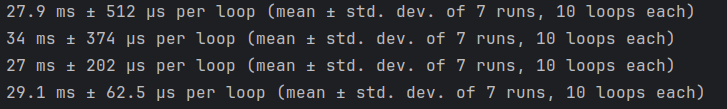
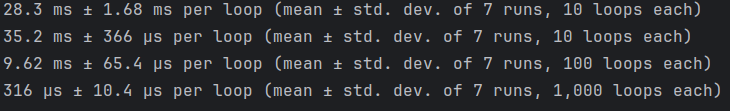

### 🟢 Zadanie 5: operacje na tablicach

Dana jest tablica `x` z pomiarami temperatury (°C).

1. Policz średnią, odchylenie standardowe, minimum i maksimum.
2. Wybierz pomiary wyższe od średniej. Ile ich jest?
3. **Normalizacja min–max:** przeskaluj `x` do przedziału $[0, 1]$: $\;x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$
4. **Standaryzacja:** $\;z = \dfrac{x - \bar{x}}{s}$. Sprawdź, że wynik ma średnią ≈ 0 i odchylenie standardowe ≈ 1.

Wszystko bez pętli!

In [87]:
x = np.array([12.5, 14.0, 9.8, 17.3, 15.1, 11.2, 18.6, 16.0, 13.4, 10.9])


print("średnia =", round(x.mean(), 2), ", odch. std =", round(x.std(), 2), ", min =", x.min(), ", max =", x.max())

# np.set_printoptions(floatmode="fixed", precision=1)

powyzej = x[x > x.mean()]
print("powyżej średniej:", powyzej, " jest ich:", len(powyzej))


x_minmax = (x - x.min()) / (x.max() - x.min())
print("min-max:", np.round(x_minmax, 3))
print("zakres:", x_minmax.min(), x_minmax.max())



z = (x - x.mean()) / x.std()
print("standaryzacja:", np.round(z, 3))
print(f"średnia z = {z.mean():.2e}, odch. std z = {z.std():.4f}")
print("średnia ≈ 0:", np.isclose(z.mean(), 0), "| std ≈ 1:", np.isclose(z.std(), 1))

średnia = 13.88 , odch. std = 2.74 , min = 9.8 , max = 18.6
powyżej średniej: [14.0 17.3 15.1 18.6 16.0]  jest ich: 5
min-max: [0.3 0.5 0.0 0.9 0.6 0.2 1.0 0.7 0.4 0.1]
zakres: 0.0 1.0
standaryzacja: [-0.5  0.0 -1.5  1.2  0.4 -1.0  1.7  0.8 -0.2 -1.1]
średnia z = -1.78e-16, odch. std z = 1.0000
średnia ≈ 0: True | std ≈ 1: True


### 🟢 Zadanie 6: rzuty kostką

1. Zasymuluj 10 000 rzutów kostką do gry (`rng.integers`).
2. Policz, ile razy wypadła każda liczba oczek (wskazówka: `np.unique(..., return_counts=True)`) i jaki to odsetek wszystkich rzutów.
3. Policz średnią liczbę oczek. Jakiej wartości się spodziewasz?

🔵 **Dla ambitnych:** zasymuluj 10 000 rzutów **dwiema** kostkami i policz rozkład sumy oczek. Która suma wypada najczęściej i dlaczego?

In [88]:
rng = np.random.default_rng(seed=1)

rzuty = rng.integers(1, 7, size=10_000)

oczka, liczebnosc = np.unique(rzuty, return_counts=True)
for o, l in zip(oczka, liczebnosc):
    print(o, "oczek:", l, "razy (", round(l / len(rzuty) * 100, 2), "% )")

#(oczekiwana: (1+2+...+6)/6 = 3.5)
print("średnia =", round(rzuty.mean(), 3), " (oczekiwana: 3.5)")

1 oczek: 1695 razy ( 16.95 % )
2 oczek: 1634 razy ( 16.34 % )
3 oczek: 1668 razy ( 16.68 % )
4 oczek: 1628 razy ( 16.28 % )
5 oczek: 1717 razy ( 17.17 % )
6 oczek: 1658 razy ( 16.58 % )
średnia = 3.501  (oczekiwana: 3.5)


---
# 3. pandas — pierwsze kroki

**pandas** służy do pracy z danymi tabelarycznymi. Podstawowe struktury:
- `Series` — jedna kolumna (wektor z etykietami),
- `DataFrame` — tabela, czyli zbiór kolumn o wspólnym indeksie.

### DataFrame ze słownika

In [89]:
dane = {
    "miasto": ["Warszawa", "Kraków", "Łódź", "Wrocław", "Poznań"],
    "ludnosc_2021": [1_860_281, 800_653, 670_642, 674_079, 546_859],
    "powierzchnia_km2": [517, 327, 293, 293, 262],
}
miasta = pd.DataFrame(dane)
miasta

,miasto,ludnosc_2021,powierzchnia_km2
0,Warszawa,1860281,517
1,Kraków,800653,327
2,Łódź,670642,293
3,Wrocław,674079,293
4,Poznań,546859,262


In [90]:
# Nowa kolumna obliczona z innych kolumn
miasta["gestosc"] = miasta["ludnosc_2021"] / miasta["powierzchnia_km2"]
miasta.sort_values("gestosc", ascending=False)

,miasto,ludnosc_2021,powierzchnia_km2,gestosc
0,Warszawa,1860281,517,3598.222437
1,Kraków,800653,327,2448.480122
3,Wrocław,674079,293,2300.610922
2,Łódź,670642,293,2288.880546
4,Poznań,546859,262,2087.248092


In [91]:
# Zapis do pliku CSV i ponowne wczytanie
miasta.to_csv("miasta.csv", index=False)
pd.read_csv("miasta.csv")

,miasto,ludnosc_2021,powierzchnia_km2,gestosc
0,Warszawa,1860281,517,3598.222437
1,Kraków,800653,327,2448.480122
2,Łódź,670642,293,2288.880546
3,Wrocław,674079,293,2300.610922
4,Poznań,546859,262,2087.248092


### Prawdziwy zbiór danych: `tips`

Zbiór `tips` zawiera 244 rachunki z restauracji, zapisane przez kelnera w ciągu kilku tygodni.

| kolumna | znaczenie |
|---|---|
| `total_bill` | kwota rachunku (USD) |
| `tip` | napiwek (USD) |
| `sex` | płeć płacącego |
| `smoker` | czy przy stoliku palono |
| `day` | dzień tygodnia |
| `time` | pora: lunch / obiad |
| `size` | liczba osób przy stoliku |

In [92]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Pierwszy rzut oka na dane

In [93]:
print(df.shape)     # (liczba wierszy, liczba kolumn)
df.info()           # typy kolumn i liczba niepustych wartości

(244, 7)
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [94]:
df.describe()       # statystyki opisowe kolumn liczbowych

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


### Wybieranie kolumn i wierszy

In [95]:
df["tip"].head()                    # jedna kolumna -> Series

0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

In [96]:
df[["total_bill", "tip"]].head()    # kilka kolumn -> DataFrame (podwójne nawiasy!)

,total_bill,tip
0,16.99,1.01
1,10.34,1.66
2,21.01,3.50
3,23.68,3.31
4,24.59,3.61


In [97]:
print(df["tip"].mean(), df["tip"].max())   # metody kolumny

2.99827868852459 10.0


### `loc` czy `iloc`?

- `iloc` — wybiera po **pozycji** (0, 1, 2, …),
- `loc` — wybiera po **etykiecie indeksu**.

Póki indeks to 0, 1, 2, …, oba dają to samo. Różnica wychodzi na jaw po posortowaniu:

In [98]:
posortowane = df.sort_values("tip", ascending=False)
posortowane.head(3)

,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
23,39.42,7.58,Male,No,Sat,Dinner,4


In [99]:
print("iloc[0] — pierwszy wiersz po posortowaniu (najwyższy napiwek):")
print(posortowane.iloc[0], "\n")

print("loc[0] — wiersz o etykiecie 0 (pierwszy rachunek w danych):")
print(posortowane.loc[0])

iloc[0] — pierwszy wiersz po posortowaniu (najwyższy napiwek):
total_bill     50.81
tip             10.0
sex             Male
smoker           Yes
day              Sat
time          Dinner
size               3
Name: 170, dtype: object 

loc[0] — wiersz o etykiecie 0 (pierwszy rachunek w danych):
total_bill     16.99
tip             1.01
sex           Female
smoker            No
day              Sun
time          Dinner
size               2
Name: 0, dtype: object


### Filtrowanie

Warunki łączymy operatorami `&` (i), `|` (lub), `~` (nie) — każdy warunek **w nawiasach**.

In [100]:
duze_rachunki = df[df["total_bill"] > 40]
duze_rachunki

,total_bill,tip,sex,smoker,day,time,size
59,48.27,6.73,Male,No,Sat,Dinner,4
95,40.17,4.73,Male,Yes,Fri,Dinner,4
102,44.30,2.50,Female,Yes,Sat,Dinner,3
142,41.19,5.00,Male,No,Thur,Lunch,5
156,48.17,5.00,Male,No,Sun,Dinner,6
170,50.81,10.00,Male,Yes,Sat,Dinner,3
182,45.35,3.50,Male,Yes,Sun,Dinner,3
184,40.55,3.00,Male,Yes,Sun,Dinner,2
197,43.11,5.00,Female,Yes,Thur,Lunch,4
212,48.33,9.00,Male,No,Sat,Dinner,4


In [101]:
sobota_obiad = df[(df["day"] == "Sat") & (df["time"] == "Dinner")]
print(len(sobota_obiad), "rachunków w sobotę na obiedzie")

87 rachunków w sobotę na obiedzie


In [102]:
# Z .loc: wiersze spełniające warunek i wybrane kolumny
df.loc[df["size"] >= 5, ["total_bill", "tip", "size"]]

,total_bill,tip,size
125,29.80,4.20,6
141,34.30,6.70,6
142,41.19,5.00,5
143,27.05,5.00,6
155,29.85,5.14,5
156,48.17,5.00,6
185,20.69,5.00,5
187,30.46,2.00,5
216,28.15,3.00,5


In [103]:
df["day"].value_counts()    # ile razy występuje każda wartość

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

### 🟢 Zadanie 7: pytania do zbioru `tips`

Odpowiedz kodem:

1. Ile wierszy i kolumn ma zbiór? Jakie są nazwy kolumn?
2. Jaki jest średni, najmniejszy i największy rachunek?
3. Ile rachunków pochodzi z niedzieli (`"Sun"`)?
4. Pokaż 5 najwyższych rachunków.
5. Dodaj kolumnę `tip_pct` — napiwek jako procent rachunku. Jaki jest średni `tip_pct`?
6. Ile rachunków ma napiwek wyższy niż 20% rachunku?

🔵 **Dla ambitnych:**

7. Jaki jest średni `tip_pct` dla lunchu, a jaki dla obiadu? (Użyj filtrowania.)
8. Dodaj kolumnę `rachunek_na_osobe`. Przy którym stoliku rachunek na osobę był najwyższy?

In [104]:
dane_ludnosc = {
    "Rok": [2002, 2011, 2015, 2021],
    "Warszawa": [1_672_000, 1_700_612, 1_740_000, 1_860_281],
    "Łódź": [789_318, 728_892, np.nan, 670_642],
}
ludnosc = pd.DataFrame(dane_ludnosc)
display(ludnosc)

ludnosc.to_csv("ludnosc.csv", index=False)
ludnosc = pd.read_csv("ludnosc.csv")
display(ludnosc)

print(ludnosc.dtypes, "\n")
print("braki danych:\n", ludnosc.isna().sum())

l = ludnosc.set_index("Rok")
zmiana = (l.loc[2021] / l.loc[2011] - 1) * 100
print("\nzmiana ludności 2011 -> 2021 [%]:")
print(zmiana.round(2))

zly = pd.DataFrame({**dane_ludnosc, "Łódź": [789_318, 728_892, "brak danych", 670_642]})
print("\ntyp kolumny Łódź z tekstem:", zly["Łódź"].dtype)

zly["Łódź"] = pd.to_numeric(zly["Łódź"], errors="coerce")
print("typ po pd.to_numeric(errors='coerce'):", zly["Łódź"].dtype)
print("braki po naprawie:", zly["Łódź"].isna().sum())

,Rok,Warszawa,Łódź
0,2002,1672000,789318.0
1,2011,1700612,728892.0
2,2015,1740000,NaN
3,2021,1860281,670642.0


,Rok,Warszawa,Łódź
0,2002,1672000,789318.0
1,2011,1700612,728892.0
2,2015,1740000,NaN
3,2021,1860281,670642.0


Rok           int64
Warszawa      int64
Łódź        float64
dtype: object 

braki danych:
 Rok         0
Warszawa    0
Łódź        1
dtype: int64

zmiana ludności 2011 -> 2021 [%]:
Warszawa    9.39
Łódź       -7.99
dtype: float64

typ kolumny Łódź z tekstem: object
typ po pd.to_numeric(errors='coerce'): float64
braki po naprawie: 1


Jeśli zamiast np.nan wpiszę tekst „brak danych”, kolumna Łódź będzie miała typ object, ponieważ będzie zawierać tekst zamiast samych liczb. Można to naprawić za pomocą pd.to_numeric(kolumna, errors="coerce"), które zamieni tekst na NaN i umożliwi poprawne wykonywanie obliczeń.

---
# Podsumowanie

Po tych zajęciach potrafisz:
- [ ] posługiwać się listami, słownikami, pętlami, funkcjami i list comprehension,
- [ ] tworzyć tablice NumPy, liczyć na nich bez pętli i losować liczby,
- [ ] wczytać dane do pandas, obejrzeć je (`head`, `info`, `describe`) i wybierać wiersze oraz kolumny,
- [ ] tworzyć nowe kolumny i zapisywać dane do pliku CSV,
- [ ] narysować wykres liniowy, punktowy, słupkowy i histogram — z opisami osi.

**Do oddania:** ten notatnik z rozwiązanymi zadaniami 🟢 w Twoim repozytorium na GitHubie.